In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

In [2]:
DATA = "/kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360"
selected_classes = ['Apple Red 1', 'Banana 1', 'Grape White 1', 'Mango 1', 'Orange 1', 'Strawberry 1', 'Tomato 1', 'Watermelon 1', 'Pear 1', 
                    'Pineapple 1']

train_ds = keras.utils.image_dataset_from_directory(
    DATA + '/Training',
    class_names=selected_classes,
    image_size=(224, 224),
    batch_size=32
)

test_ds = keras.utils.image_dataset_from_directory(
    DATA + '/Test',
    class_names=selected_classes,
    image_size=(224, 224),
    batch_size=32
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

Found 5128 files belonging to 10 classes.
Found 1719 files belonging to 10 classes.
Classes: ['Apple Red 1', 'Banana 1', 'Grape White 1', 'Mango 1', 'Orange 1', 'Strawberry 1', 'Tomato 1', 'Watermelon 1', 'Pear 1', 'Pineapple 1']


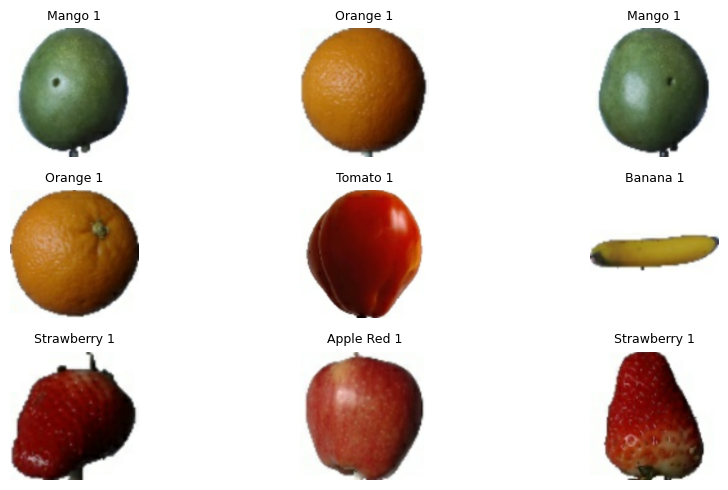

In [14]:
plt.figure(figsize=(10, 5))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])], fontsize=9)
        plt.axis('off')
        
plt.tight_layout()
plt.show()

In [4]:
train_dataset = train_ds.map(lambda x, y: (x / 255.0, y)).cache().prefetch(tf.data.AUTOTUNE)
test_datatset  = test_ds.map(lambda x, y: (x / 255.0, y)).cache().prefetch(tf.data.AUTOTUNE)

In [5]:
def model_build(base_model, name):
    base = base_model(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base.trainable = False
    
    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax') 
    ])

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [6]:
resnet_model  = model_build(keras.applications.ResNet50, "ResNet50")
densenet_model = model_build(keras.applications.DenseNet121, "DenseNet121")

In [7]:
resnet_training = resnet_model.fit(train_ds, epochs=5)

Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 33s 129ms/step - accuracy: 0.9499 - loss: 0.1892
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 98ms/step - accuracy: 0.9988 - loss: 0.0114
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 15s 95ms/step - accuracy: 0.9992 - loss: 0.0053
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 15s 93ms/step - accuracy: 0.9994 - loss: 0.0044
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 15s 92ms/step - accuracy: 1.0000 - loss: 0.0027


In [8]:
densenet_training = densenet_model.fit(train_ds, epochs=5)

Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 161ms/step - accuracy: 0.7929 - loss: 1.2453
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 13s 83ms/step - accuracy: 0.9649 - loss: 0.1206
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9791 - loss: 0.0716
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 13s 82ms/step - accuracy: 0.9826 - loss: 0.0576
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 13s 81ms/step - accuracy: 0.9821 - loss: 0.0528


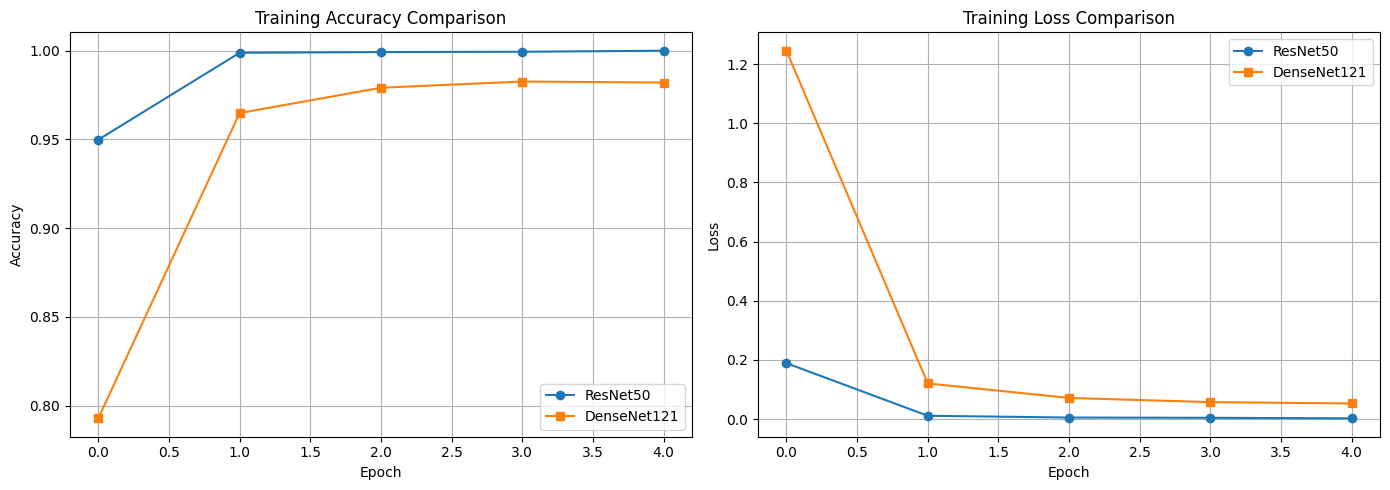

In [9]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(resnet_training.history['accuracy'], 'o-', label='ResNet50')
plt.plot(densenet_training.history['accuracy'], 's-', label='DenseNet121')
plt.title('Training Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(resnet_training.history['loss'], 'o-', label='ResNet50')
plt.plot(densenet_training.history['loss'], 's-', label='DenseNet121')
plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
def evaluate(model, dataset, name):
    loss, acc = model.evaluate(dataset, verbose=0)
    y_true, y_pred = [], []
    
    for imgs, lbls in dataset:
        preds = model.predict(imgs, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(lbls.numpy())

    print(f"{name}  —  Loss: {loss:.4f}  |  Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=class_names))
    return {'loss': loss, 'accuracy': acc}

In [11]:
resnet50 = evaluate(resnet_model, test_ds, "ResNet50")

ResNet50  —  Loss: 0.0001  |  Accuracy: 1.0000
               precision    recall  f1-score   support

  Apple Red 1       1.00      1.00      1.00       164
     Banana 1       1.00      1.00      1.00       166
Grape White 1       1.00      1.00      1.00       166
      Mango 1       1.00      1.00      1.00       166
     Orange 1       1.00      1.00      1.00       160
 Strawberry 1       1.00      1.00      1.00       164
     Tomato 1       1.00      1.00      1.00       246
 Watermelon 1       1.00      1.00      1.00       157
       Pear 1       1.00      1.00      1.00       164
  Pineapple 1       1.00      1.00      1.00       166

     accuracy                           1.00      1719
    macro avg       1.00      1.00      1.00      1719
 weighted avg       1.00      1.00      1.00      1719



In [12]:
densenet = evaluate(densenet_model, test_ds, "DenseNet121")

DenseNet121  —  Loss: 0.0005  |  Accuracy: 1.0000
               precision    recall  f1-score   support

  Apple Red 1       1.00      1.00      1.00       164
     Banana 1       1.00      1.00      1.00       166
Grape White 1       1.00      1.00      1.00       166
      Mango 1       1.00      1.00      1.00       166
     Orange 1       1.00      1.00      1.00       160
 Strawberry 1       1.00      1.00      1.00       164
     Tomato 1       1.00      1.00      1.00       246
 Watermelon 1       1.00      1.00      1.00       157
       Pear 1       1.00      1.00      1.00       164
  Pineapple 1       1.00      1.00      1.00       166

     accuracy                           1.00      1719
    macro avg       1.00      1.00      1.00      1719
 weighted avg       1.00      1.00      1.00      1719



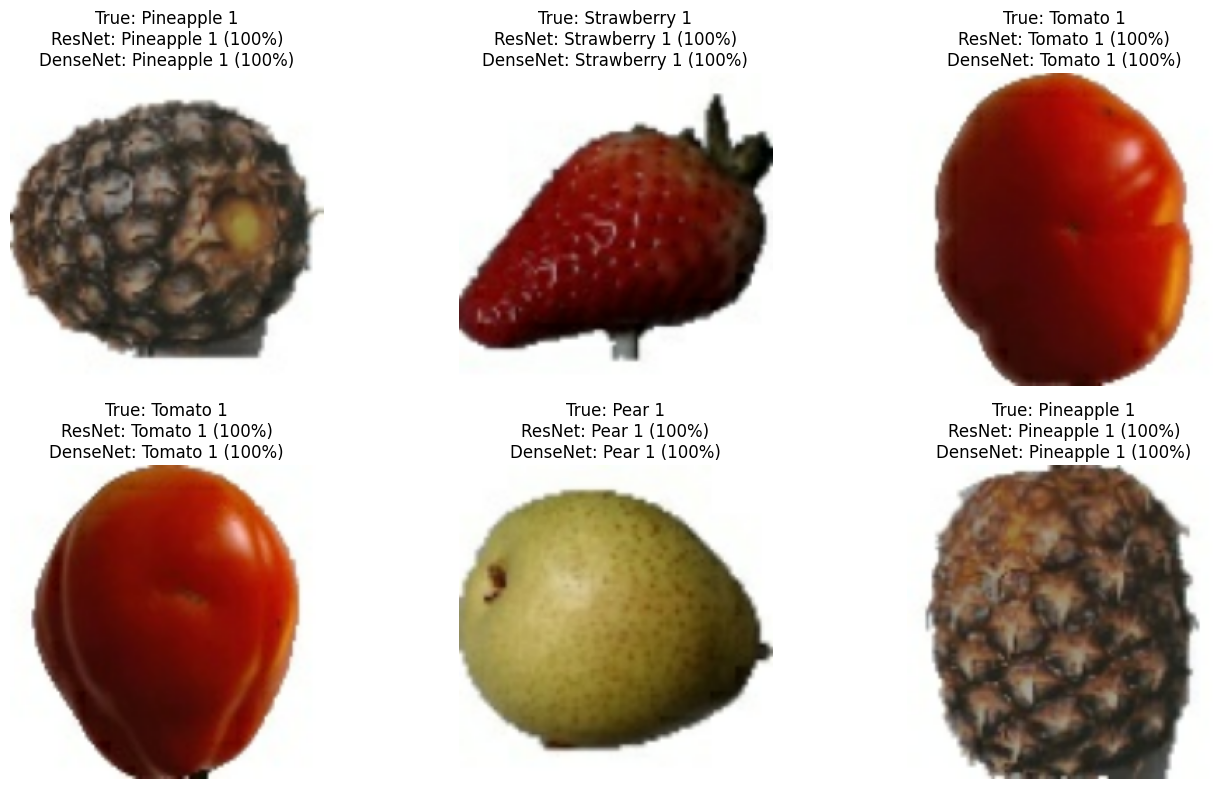

In [13]:
for test_imgs, test_lbls in test_ds.take(1):
    res_preds = resnet_model.predict(test_imgs, verbose=0)
    den_preds = densenet_model.predict(test_imgs, verbose=0)

    plt.figure(figsize=(14, 8))
    for i in range(min(6, len(test_imgs))):
        plt.subplot(2, 3, i + 1)
        plt.imshow(test_imgs[i].numpy().astype("uint8"))

        true  = class_names[int(test_lbls[i])]
        r_cls = class_names[np.argmax(res_preds[i])]
        d_cls = class_names[np.argmax(den_preds[i])]

        plt.title(f"True: {true}\n" f"ResNet: {r_cls} ({np.max(res_preds[i])*100:.0f}%)\n" f"DenseNet: {d_cls} ({np.max(den_preds[i])*100:.0f}%)")
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()